In [20]:
from sklearn.datasets import load_iris

# Load directly as a structured Pandas DataFrame
iris_data = load_iris(as_frame=True)
df = iris_data.frame

# Display the continuous features to be discretized
print(df.head(), df.shape)

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target  
0       0  
1       0  
2       0  
3       0  
4       0   (150, 5)


In [21]:
import numpy as np

# Feature discretization

X = iris_data.data
feature_names = iris_data.feature_names

binned_features = np.zeros_like(X, dtype=int)
for i in range(X.shape[1]):
    col = X.iloc[:, i].to_numpy()

    bins = np.linspace(col.min(), col.max(), 11)    # Create 11 edges for 10 bins

    binned = np.digitize(col, bins, right=True) - 1     # 1-indexed to 0-indexed
    binned_features[: ,i] = np.clip(binned, 0, 9)

# Calculate pmfs
pmfs = []
for i in range(X.shape[1]):
    counts = np.bincount(binned_features[: ,i], minlength=10)
    pmf = counts / len(binned_features)
    pmfs.append(pmf)

print(f"PMF of First feature: {pmfs[0]}")
print(f"Sum of pmfs of first feature = {sum(pmfs[0])}")

PMF of First feature: [0.06       0.15333333 0.09333333 0.18       0.14666667 0.13333333
 0.12       0.04       0.03333333 0.04      ]
Sum of pmfs of first feature = 1.0


In [22]:
def entropy(p):
    p = p[p > 0]    # Filter out 0 probability to avoid log 0
    return -np.sum(p * np.log2(p))

def joint_entropy(p_xy):
    p_xy = p_xy[p_xy > 0]
    return -np.sum(p_xy * np.log2(p_xy))

def mutual_information(x, y):
    # I(x, y) = H(x) + H(y) - H(x, y)
    bins = 10

    # compute joint counts
    counts, _, _ = np.histogram2d(x, y, bins=bins, range=[[0, bins], [0, bins]])
    p_xy = counts / len(x)

    p_x = np.sum(p_xy, axis=1)
    p_y = np.sum(p_xy, axis=0)

    h_x = entropy(p_x)
    h_y = entropy(p_y)
    h_xy = joint_entropy(p_xy)

    return h_x + h_y - h_xy

sample = mutual_information(binned_features[:, 0], binned_features[:, 2])
print(f"Mutual information between {feature_names[0]} and {feature_names[2]} = {sample}")
print(f"Entropy of {feature_names[0]} = {entropy(binned_features[:, 0])}")
print(f"Entropy of {feature_names[2]} = {entropy(binned_features[:, 2])}")

Mutual information between sepal length (cm) and petal length (cm) = 1.2966720934458378
Entropy of sepal length (cm) = -1252.8355789293387
Entropy of petal length (cm) = -1590.2721352114909


[[3.11888483 0.68935947 1.29667209 1.06365665]
 [0.68935947 2.7733349  0.70178823 0.87881258]
 [1.29667209 0.70178823 2.84598337 1.57275009]
 [1.06365665 0.87881258 1.57275009 2.93966977]]


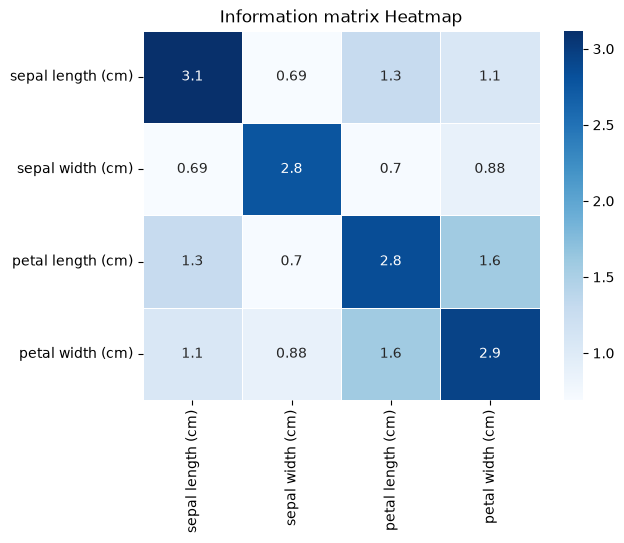

In [23]:
n_features = X.shape[1]
info_matrix = np.zeros((n_features, n_features))    # 4 x 4 matrix

for i in range(n_features):
    for j in range(n_features):
        info_matrix[i][j] = mutual_information(binned_features[:,i], binned_features[:,j])

print(info_matrix)

import matplotlib.pyplot as plt
import seaborn as sns

sns.heatmap(info_matrix, annot=True, cmap='Blues', linewidths=0.5, xticklabels=feature_names, yticklabels=feature_names)
plt.title("Information matrix Heatmap")
plt.xlabel = "Features"
plt.ylabel = "Features"

plt.show()

In [24]:
# Mask diagonal values
np.fill_diagonal(info_matrix, -1)

i, j = np.unravel_index(np.argmax(info_matrix), info_matrix.shape)

print(f"Feature pair with highest mutual information value are {feature_names[i]} and {feature_names[j]}")

Feature pair with highest mutual information value are petal length (cm) and petal width (cm)
